<a href="https://colab.research.google.com/github/leandroxxxxx/lowres-plate-char-classification/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Donwload arquivos Drive

In [ ]:
manifest_drive_id = "1MDNgZVubmLU0yAiHGpsxETK9B2EwvO8E"
manifest_output = "manifest.csv"

dataset_drive_id = "1VA0xY422FFmq-YDzMHXevH0qLA2sB34Y"
dataset_output = "img.zip"

In [ ]:
%%capture
import gdown

gdown.download(
    id=manifest_drive_id,
    output=manifest_output,
    quiet=False
)

gdown.download(
    id=dataset_drive_id,
    output=dataset_output,
    quiet=False
)

## 1 Environment

In [ ]:
import json
import os
import random
import time
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models


def set_seed(seed: int) -> None:
    """Seed every random number generator used in the notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(
    f"torch {torch.__version__} | torchvision {torchvision.__version__} | "
    f"opencv {cv2.__version__} | pandas {pd.__version__}"
)
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB")
else:
    print("WARNING: no GPU found. In Colab: Runtime > Change runtime type > GPU.")

torch 2.14.1+cpu | torchvision 0.29.1+cpu | opencv 5.0.0 | pandas 2.2.3
Device: cpu


## 2 - Configuration

In [ ]:

# %%
# ---------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------
SEED = 42

# ---------------------------------------------------------------
# Paths (files downloaded by the gdown cell land in /content)
# ---------------------------------------------------------------
WORK_DIR = Path("/content")
MANIFEST_PATH = WORK_DIR / "manifest.csv"
ZIP_PATH = WORK_DIR / "img.zip"
EXTRACT_DIR = WORK_DIR                  # the zip already contains the "img" folder
IMG_DIR = EXTRACT_DIR / "img"
OUTPUT_DIR = WORK_DIR / "outputs"       # checkpoints, split CSV, results

# ---------------------------------------------------------------
# Classes
# ---------------------------------------------------------------
LETTERS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
DIGITS = list("0123456789")
ALL_CLASSES = LETTERS + DIGITS          # indices 0-25 = A-Z, 26-35 = 0-9
CLASS_TO_IDX = {c: i for i, c in enumerate(ALL_CLASSES)}
NUM_CLASSES = len(ALL_CLASSES)          # 36 outputs, fixed so rare classes can be added later

# Dropped from training because they have too few samples.
# Classes with no samples at all (e.g. "M") are detected from the manifest in Cell 6.
EXCLUDED_LABELS = ["Z", "K", "X", "W", "L"]

# ---------------------------------------------------------------
# Input size (crops are 9:16, width:height)
# ---------------------------------------------------------------
INPUT_PRESETS = {"small": (36, 64), "large": (45, 80)}  # (width, height)
INPUT_PRESET = "small"
INPUT_W, INPUT_H = INPUT_PRESETS[INPUT_PRESET]

# ---------------------------------------------------------------
# Split (random, stratified by label; no group separation in this version)
# ---------------------------------------------------------------
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9

# ---------------------------------------------------------------
# Training
# ---------------------------------------------------------------
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
SCHEDULER = "cosine"                    # "cosine" or "onecycle"
EARLY_STOP_PATIENCE = 8                 # epochs without val improvement; None disables
NUM_WORKERS = 0                         # images are cached in RAM, workers only add overhead

# ---------------------------------------------------------------
# Switches
# ---------------------------------------------------------------
USE_PRETRAINED = True                   # ImageNet weights for the ResNet18
USE_AMP = True                          # mixed precision, only effective on CUDA
USE_CLASS_WEIGHTS = False               # round 1 runs without class weights

USE_AMP = USE_AMP and DEVICE.type == "cuda"

# ---------------------------------------------------------------
# Setup
# ---------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

print(f"Seed: {SEED}")
print(f"Manifest: {MANIFEST_PATH} (exists: {MANIFEST_PATH.exists()})")
print(f"Zip: {ZIP_PATH} (exists: {ZIP_PATH.exists()})")
print(f"Images dir: {IMG_DIR}")
print(f"Outputs dir: {OUTPUT_DIR}")
print(f"Input size (W x H): {INPUT_W} x {INPUT_H} [{INPUT_PRESET}]")
print(f"Split train/val/test: {TRAIN_FRAC}/{VAL_FRAC}/{TEST_FRAC}")
print(
    f"Batch {BATCH_SIZE} | epochs {EPOCHS} | lr {LEARNING_RATE} | "
    f"wd {WEIGHT_DECAY} | scheduler {SCHEDULER} | patience {EARLY_STOP_PATIENCE}"
)
print(
    f"Pretrained: {USE_PRETRAINED} | AMP: {USE_AMP} | "
    f"Class weights: {USE_CLASS_WEIGHTS}"
)
print(f"Excluded labels: {EXCLUDED_LABELS}")


Seed: 42
Manifest: /content/manifest.csv (exists: True)
Zip: /content/img.zip (exists: True)
Images dir: /content/img
Outputs dir: /content/outputs
Input size (W x H): 36 x 64 [small]
Split train/val/test: 0.7/0.15/0.15
Batch 64 | epochs 30 | lr 0.0003 | wd 0.01 | scheduler cosine | patience 8
Pretrained: True | AMP: False | Class weights: False
Excluded labels: ['Z', 'K', 'X', 'W', 'L']


## 3 - Extract the dataset

In [ ]:
# %%
import shutil
from collections import Counter

# Set to True to force a fresh extraction even if the images are already there.
FORCE_EXTRACT = False

# ---------------------------------------------------------------
# 1) Preconditions
# ---------------------------------------------------------------
# The gdown cell (before Cell 1) must have run first. Failing early with a clear
# message is much better than a cryptic error three cells later.
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH} not found. Run the gdown download cell first."
    )

# ---------------------------------------------------------------
# 2) Extract to the Colab *local* disk
# ---------------------------------------------------------------

already_extracted = IMG_DIR.exists() and any(IMG_DIR.rglob("*.png"))

if already_extracted and not FORCE_EXTRACT:
    print(f"Images already extracted in {IMG_DIR}, skipping extraction.")
else:
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f"{ZIP_PATH} not found. Run the gdown download cell first."
        )
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as zf:
        members = zf.namelist()
        print(f"Zip has {len(members)} entries. First ones: {members[:3]}")
        # extractall recreates the folder structure stored inside the zip, so with
        # EXTRACT_DIR = /content we expect to end up with /content/img/...
        zf.extractall(EXTRACT_DIR)
    print(f"Extracted in {time.time() - t0:.1f}s")

# ---------------------------------------------------------------
# 3) Verify the layout
# ---------------------------------------------------------------

if not IMG_DIR.exists():
    found = sorted(p.name for p in EXTRACT_DIR.iterdir())
    raise FileNotFoundError(
        f"Expected folder {IMG_DIR} after extraction. "
        f"Contents of {EXTRACT_DIR}: {found}. "
        "Adjust IMG_DIR (Cell 2) to match the zip structure."
    )

files = [p for p in IMG_DIR.rglob("*") if p.is_file()]

# Count files by extension: catches stray files (Thumbs.db, .DS_Store, etc.)
# and confirms that the images really are PNGs.
suffix_counts = Counter(p.suffix.lower() for p in files)
n_png = suffix_counts.get(".png", 0)
assert n_png > 0, f"No PNG files found under {IMG_DIR}. Extensions found: {dict(suffix_counts)}"

# Are the PNGs directly inside img/ or in subfolders? Cell 4 needs this to rebuild
# the full path of each image from the manifest "path" column.
subfolders = sorted({str(p.parent.relative_to(IMG_DIR)) for p in files})
size_mb = sum(p.stat().st_size for p in files) / 1024**2
free_gb = shutil.disk_usage(WORK_DIR).free / 1024**3

print(f"\nFiles by extension: {dict(suffix_counts)}")
print(f"PNG files: {n_png} | total size: {size_mb:.1f} MB | free disk: {free_gb:.1f} GB")
print(f"Subfolders under img/ ('.' means files sit directly in img/): {subfolders[:5]}")
print("Sample files:")
for p in sorted(files)[:3]:
    print("  ", p.relative_to(EXTRACT_DIR))

Zip has 5554 entries. First ones: ['img/', 'img/261022215621_759590_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_1_r.png', 'img/261022215621_760496_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_2_e.png']
Extracted in 0.4s

Files by extension: {'.png': 5553}
PNG files: 5553 | total size: 1.3 MB | free disk: 225.7 GB
Subfolders under img/ ('.' means files sit directly in img/): ['.']
Sample files:
   img/261022215621_759590_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_1_r.png
   img/261022215621_760496_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_2_e.png
   img/261022215621_760977_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_3_d.png


## 4 - Load and filter the manifest

Rows in manifest: 5553
Rows whose image was not found: 0
Images on disk with no manifest row: 0

char_type vs label kind (rows: char_type, columns: is_letter):
is_letter  False  True 
char_type              
digit       2394      0
letter         0   3159
OK: each char_type value maps to a single kind (letter or digit).

Removing 124 rows of excluded classes:
label
Z    34
K    33
X    22
W    22
L    13

Final dataset: 5429 crops | 30 classes (20 letters + 10 digits) | 27 groups
Samples per class: min 61 (U) | max 533 (1) | ratio 9x


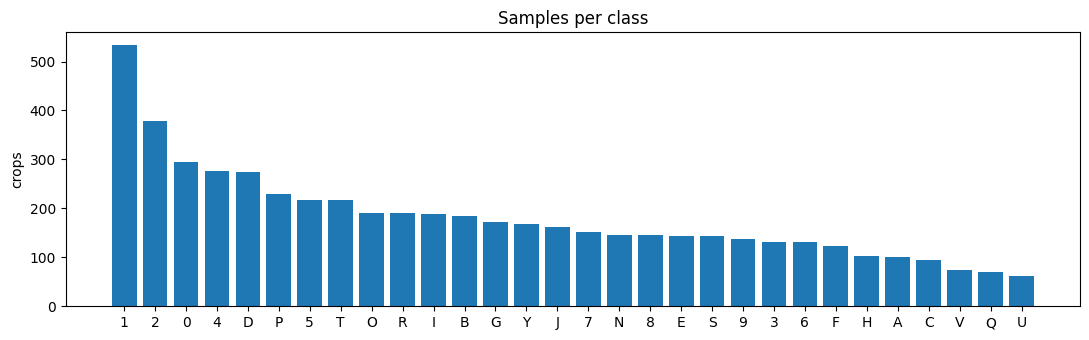

,crop_id,path,label,char_type,position,plate_text,source_stem,video_name,frame_time_s,group_id,frame_index,orig_h,orig_w,lighting,brightness,file_name,img_path,is_letter
0,261022215621_759590,261022215621_759590_0001_AVI3788.avi_00-00-03....,R,letter,1,RED1C71,0001_AVI3788.avi_00-00-03.400,AVI3788.avi,3.4,AVI3788.avi_RED1C71,16,14,8,light,normal,261022215621_759590_0001_AVI3788.avi_00-00-03....,/content/img/261022215621_759590_0001_AVI3788....,True
1,261022215621_760496,261022215621_760496_0001_AVI3788.avi_00-00-03....,E,letter,2,RED1C71,0001_AVI3788.avi_00-00-03.400,AVI3788.avi,3.4,AVI3788.avi_RED1C71,16,14,8,light,normal,261022215621_760496_0001_AVI3788.avi_00-00-03....,/content/img/261022215621_760496_0001_AVI3788....,True
2,261022215621_760977,261022215621_760977_0001_AVI3788.avi_00-00-03....,D,letter,3,RED1C71,0001_AVI3788.avi_00-00-03.400,AVI3788.avi,3.4,AVI3788.avi_RED1C71,16,14,8,light,normal,261022215621_760977_0001_AVI3788.avi_00-00-03....,/content/img/261022215621_760977_0001_AVI3788....,True


In [ ]:
# ---------------------------------------------------------------
# 1) Load the manifest
# ---------------------------------------------------------------
# dtype=str on the text columns is defensive: labels such as "0" or "1" must stay
# strings. If pandas ever guessed "integer" for them, "A" would break and "01"
# would silently become 1.
df = pd.read_csv(
    MANIFEST_PATH,
    dtype={"label": str, "plate_text": str, "group_id": str, "char_type": str},
)
print(f"Rows in manifest: {len(df)}")

expected_cols = [
    "crop_id", "path", "label", "char_type", "position", "plate_text",
    "source_stem", "group_id", "frame_index", "orig_h", "orig_w",
]
missing_cols = [c for c in expected_cols if c not in df.columns]
assert not missing_cols, f"Manifest is missing columns: {missing_cols}"

# Null values would break things later (e.g. orig_h is used for quantiles).
n_nulls = int(df[expected_cols].isna().sum().sum())
assert n_nulls == 0, f"Manifest has {n_nulls} null values in the key columns"
assert df["crop_id"].is_unique, "crop_id is not unique"

# ---------------------------------------------------------------
# 2) Clean and validate the labels
# ---------------------------------------------------------------
df["label"] = df["label"].str.strip().str.upper()
unknown_labels = set(df["label"]) - set(ALL_CLASSES)
assert not unknown_labels, f"Labels outside A-Z / 0-9: {unknown_labels}"

# ---------------------------------------------------------------
# 3) Resolve the image paths
# ---------------------------------------------------------------
# The "path" column was written on Windows, so it may hold backslashes, an absolute
# path like D:\...\img\x.png, or just a file name. Instead of guessing how to patch
# that string, we keep only the FILE NAME and look it up in the folder we actually
# extracted. This works no matter what the original path looked like.
files_on_disk = sorted(IMG_DIR.rglob("*.png"))
name_to_path = {p.name: str(p) for p in files_on_disk}
assert len(name_to_path) == len(files_on_disk), (
    "Duplicate file names across subfolders: matching by file name would be ambiguous"
)

df["file_name"] = df["path"].str.replace("\\", "/", regex=False).str.split("/").str[-1]
df["img_path"] = df["file_name"].map(name_to_path)  # NaN when the file is not on disk

# Two-way check: manifest rows without an image, and images without a manifest row.
missing_files = df["img_path"].isna()
orphan_files = set(name_to_path) - set(df["file_name"])
print(f"Rows whose image was not found: {int(missing_files.sum())}")
print(f"Images on disk with no manifest row: {len(orphan_files)}")
if missing_files.any():
    print("Examples of missing files:", df.loc[missing_files, "file_name"].head(5).tolist())
    df = df[~missing_files]  # keep going without them, but we have been warned

# ---------------------------------------------------------------
# 4) Is char_type consistent with the label?
# ---------------------------------------------------------------
# char_type was typed by the operator, the label comes from the plate text. They must
# agree: every letter label should have one char_type value and every digit label the
# other. We do not assume what the values are called; the crosstab shows them.
df["is_letter"] = df["label"].str.isalpha()
print("\nchar_type vs label kind (rows: char_type, columns: is_letter):")
print(pd.crosstab(df["char_type"], df["is_letter"]).to_string())
types_per_kind = df.groupby("char_type")["is_letter"].nunique()
if (types_per_kind > 1).any():
    print("WARNING: some char_type values mix letters and digits. Check the manifest.")
else:
    print("OK: each char_type value maps to a single kind (letter or digit).")

# ---------------------------------------------------------------
# 5) Drop the excluded classes
# ---------------------------------------------------------------
excluded_mask = df["label"].isin(EXCLUDED_LABELS)
print(f"\nRemoving {int(excluded_mask.sum())} rows of excluded classes:")
print(df.loc[excluded_mask, "label"].value_counts().to_string())

# reset_index matters: later cells select rows by position (splits, DataLoaders).
# A leftover gap in the index is a classic source of off-by-one mistakes.
df = df[~excluded_mask].reset_index(drop=True)

# ---------------------------------------------------------------
# 6) Final overview
# ---------------------------------------------------------------
counts = df["label"].value_counts()
n_letters = int(df.loc[df["is_letter"], "label"].nunique())
n_digits = int(df.loc[~df["is_letter"], "label"].nunique())
print(f"\nFinal dataset: {len(df)} crops | {df['label'].nunique()} classes "
      f"({n_letters} letters + {n_digits} digits) | {df['group_id'].nunique()} groups")
print(f"Samples per class: min {counts.min()} ({counts.idxmin()}) | "
      f"max {counts.max()} ({counts.idxmax()}) | ratio {counts.max() / counts.min():.0f}x")

# Seeing the imbalance is the first step to deciding how to handle it later.
plt.figure(figsize=(11, 3.5))
plt.bar(counts.index, counts.values)
plt.title("Samples per class")
plt.ylabel("crops")
plt.tight_layout()
plt.show()

df.head(3)

## 5 - Dataset inspection

PNG modes:
png_mode
RGB    5429

PNGs whose size differs from the manifest: 0 of 5429 (0.0%)
Most common PNG sizes (w, h):
png_w  png_h
5      9        719
6      10       567
       11       475
5      10       427
4      8        423

Aspect ratio w/h (expected 0.5625):
count    5429.0000
mean        0.5623
std         0.0500
min         0.4286
25%         0.5333
50%         0.5556
75%         0.6000
max         0.7143
Crops more than 5% away from 9:16: 2813

orig_h quantiles:
0.00     5.0
0.10     7.0
0.25     8.0
0.50    10.0
0.75    12.0
0.90    15.0
1.00    21.0
Candidate 4-band edges (quartiles of orig_h): [8.0, 10.0, 12.0]
Crops upscaled to INPUT_H=64: 100.0% | downscaled: 0.0%


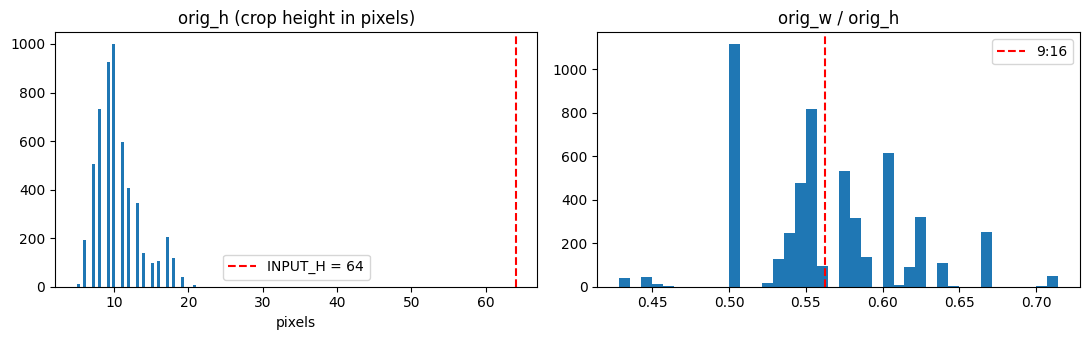

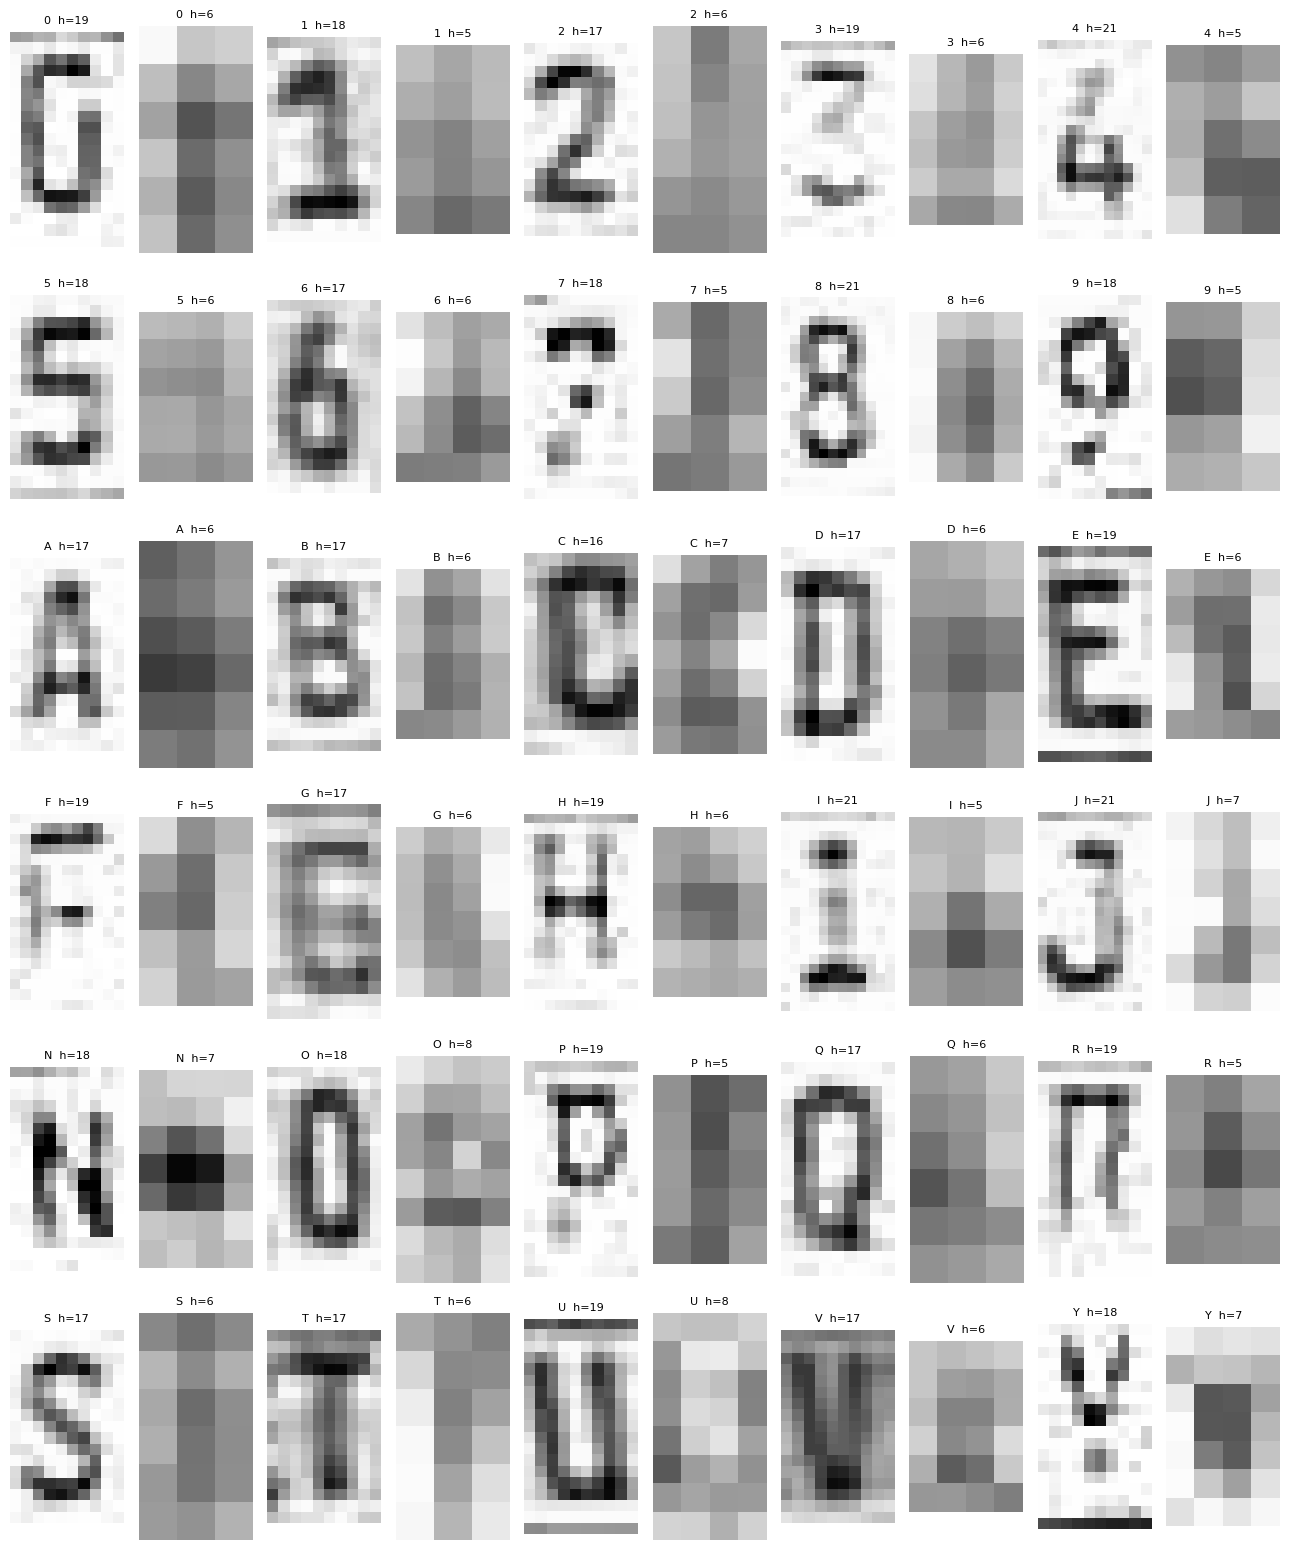


Spearman(frame_index, orig_h) over 27 groups:
count    27.000
mean      0.440
std       0.768
min      -0.942
25%      -0.244
50%       0.903
75%       0.958
max       0.980
Groups that are NOT clearly decreasing (corr > -0.5): 21
AVI3792.avi_SDQ2A25    0.980
AVI3792.avi_PRN6G80    0.978
AVI3789.avi_QUV5D92    0.975
AVI3788.avi_PUX0E55    0.973
AVI3789.avi_PRH0F33    0.972
AVI3789.avi_RBN3E71    0.969
AVI3789.avi_PRT8G20    0.961
AVI3791.avi_HPZ5D13    0.954
AVI3792.avi_TGG6E58    0.953
AVI3792.avi_SCN7E11    0.945


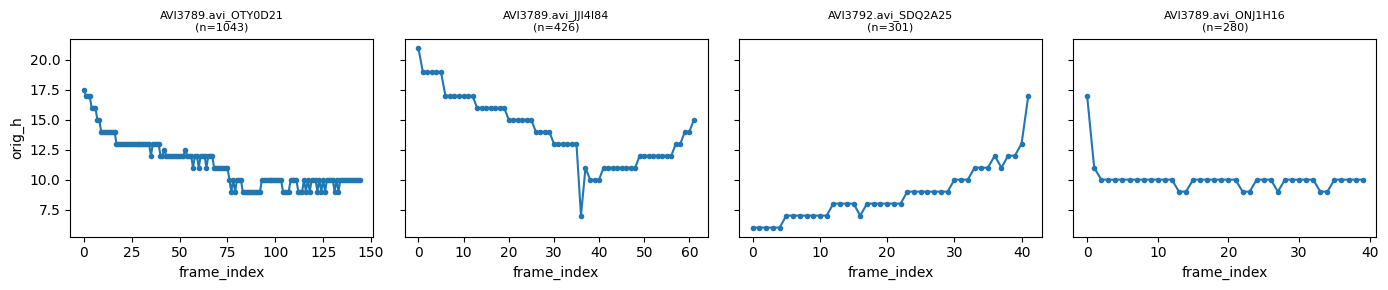

In [ ]:
from PIL import Image

# Column of `df` holding the full path of each image (built in Cell 4).
# Change this name if Cell 4 used a different one.
PATH_COL = "img_path"
REQUIRED = [PATH_COL, "label", "orig_h", "orig_w", "group_id", "frame_index"]
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"df is missing columns: {missing}"

# ---------------------------------------------------------------
# 1) Real PNG size vs the size recorded in the manifest
# ---------------------------------------------------------------
# Why this matters: orig_h is our proxy for degradation (plate height in pixels in
# the original frame). If the PNGs were resized after cropping, the PNG size no
# longer tells us the original resolution, and orig_h in the manifest is the ONLY
# record of it. If they were not resized, both must match exactly.
def read_png_info(path):
    # Image.open only reads the file header, it does not decode the pixels,
    # so this is fast even for thousands of files.
    with Image.open(path) as im:
        w, h = im.size
        return w, h, im.mode


info = [read_png_info(p) for p in df[PATH_COL]]
df[["png_w", "png_h", "png_mode"]] = pd.DataFrame(info, index=df.index)

# Mode "L" = grayscale, "RGB"/"RGBA" = color. Color is irrelevant here, but the gray
# level is not, so we will convert with cv2.IMREAD_GRAYSCALE when loading.
print("PNG modes:")
print(df["png_mode"].value_counts().to_string())

resized = (df["png_w"] != df["orig_w"]) | (df["png_h"] != df["orig_h"])
print(f"\nPNGs whose size differs from the manifest: {resized.sum()} of {len(df)} ({resized.mean():.1%})")
print("Most common PNG sizes (w, h):")
print(df.groupby(["png_w", "png_h"]).size().sort_values(ascending=False).head(5).to_string())
if resized.any():
    print("\nExamples of mismatches:")
    print(df.loc[resized, ["orig_w", "orig_h", "png_w", "png_h"]].head().to_string())

# ---------------------------------------------------------------
# 2) Aspect ratio: crops should be 9:16 (width:height = 0.5625)
# ---------------------------------------------------------------
# The protocol cuts edge to edge of the plate, so every crop should have the same
# proportion. Outliers usually mean a bad annotation.
ratio = df["orig_w"] / df["orig_h"]
off_ratio = ((ratio - 9 / 16).abs() / (9 / 16) > 0.05).sum()
print(f"\nAspect ratio w/h (expected 0.5625):")
print(ratio.describe().round(4).to_string())
print(f"Crops more than 5% away from 9:16: {off_ratio}")

# ---------------------------------------------------------------
# 3) Distribution of orig_h (our degradation proxy)
# ---------------------------------------------------------------
quantiles = df["orig_h"].quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0])
print("\norig_h quantiles:")
print(quantiles.to_string())

# Candidate edges for 4 degradation bands (used later in Cell 15).
band_edges = df["orig_h"].quantile([0.25, 0.5, 0.75]).tolist()
print(f"Candidate 4-band edges (quartiles of orig_h): {band_edges}")

# The network input height is INPUT_H. A crop smaller than that is UPSCALED
# (interpolation invents pixels, so the choice of method matters), a larger one is
# DOWNSCALED (INTER_AREA is the usual choice). This decides the method in Cell 9.
up_share = (df["orig_h"] < INPUT_H).mean()
print(f"Crops upscaled to INPUT_H={INPUT_H}: {up_share:.1%} | downscaled: {1 - up_share:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["orig_h"], bins=40)
axes[0].axvline(INPUT_H, color="red", linestyle="--", label=f"INPUT_H = {INPUT_H}")
axes[0].set_title("orig_h (crop height in pixels)")
axes[0].set_xlabel("pixels")
axes[0].legend()
axes[1].hist(ratio, bins=40)
axes[1].axvline(9 / 16, color="red", linestyle="--", label="9:16")
axes[1].set_title("orig_w / orig_h")
axes[1].legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 4) Example grid: least vs most degraded crop of each class
# ---------------------------------------------------------------
# IMPORTANT: imshow stretches contrast per image by default, which would hide the
# real gray level (and the gray level is information here). Fixing vmin/vmax to
# the full 0-255 range shows each image exactly as the network will see it.
labels = sorted(df["label"].unique())
CLASSES_PER_ROW = 5
n_rows = int(np.ceil(len(labels) / CLASSES_PER_ROW))
fig, axes = plt.subplots(
    n_rows, CLASSES_PER_ROW * 2,
    figsize=(CLASSES_PER_ROW * 2 * 1.3, n_rows * 2.6),
    squeeze=False,
)
for ax in axes.ravel():
    ax.axis("off")

for i, lab in enumerate(labels):
    r, c = divmod(i, CLASSES_PER_ROW)
    sub = df[df["label"] == lab].sort_values("orig_h")
    # Largest orig_h first (least degraded), then smallest (most degraded).
    for j, row in enumerate([sub.iloc[-1], sub.iloc[0]]):
        ax = axes[r, c * 2 + j]
        img = cv2.imread(str(row[PATH_COL]), cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{lab}  h={row['orig_h']}", fontsize=8)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 5) Sanity check: orig_h should shrink as the vehicle moves away
# ---------------------------------------------------------------
# Within each group (one plate in one video) the plate gets smaller over the frames,
# so orig_h vs frame_index should be roughly monotonic decreasing. Spearman rank
# correlation measures monotonicity: close to -1 means "decreasing", 0 means no trend.
# We take the median orig_h per frame, because the 7 characters of a plate share a frame.
def frame_corr(d):
    s = d.groupby("frame_index")["orig_h"].median()
    if len(s) < 5 or s.nunique() < 2:
        return np.nan
    return s.index.to_series().corr(s, method="spearman")


corrs = pd.Series({gid: frame_corr(d) for gid, d in df.groupby("group_id")}).dropna()
print(f"\nSpearman(frame_index, orig_h) over {len(corrs)} groups:")
print(corrs.describe().round(3).to_string())

suspicious = corrs[corrs > -0.5].sort_values(ascending=False)
print(f"Groups that are NOT clearly decreasing (corr > -0.5): {len(suspicious)}")
if len(suspicious):
    print(suspicious.head(10).round(3).to_string())

# Visual check on the 4 largest groups.
top_groups = df["group_id"].value_counts().head(4).index
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, gid in zip(axes, top_groups):
    s = df[df["group_id"] == gid].groupby("frame_index")["orig_h"].median()
    ax.plot(s.index, s.values, marker=".", linestyle="-")
    ax.set_title(f"{gid}\n(n={int((df['group_id'] == gid).sum())})", fontsize=8)
    ax.set_xlabel("frame_index")
axes[0].set_ylabel("orig_h")
plt.tight_layout()
plt.show()

## 6 - Label encoding

In [ ]:
# ---------------------------------------------------------------
# 1) Label -> class index
# ---------------------------------------------------------------
# The classifier outputs one score (logit) per class, so the labels must become
# integers. We keep the FIXED 36-index scheme from Cell 2 (A-Z = 0-25, 0-9 = 26-35)
# instead of numbering only the classes we have. Reason: the output layer always has
# 36 neurons, so when Z, K, X, W, L or M get enough data later, they plug into the
# same network shape and the same indices, and old checkpoints stay compatible.
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

df["y"] = df["label"].map(CLASS_TO_IDX)
assert df["y"].notna().all(), "Some labels have no class index"
df["y"] = df["y"].astype(int)

# ---------------------------------------------------------------
# 2) Active classes
# ---------------------------------------------------------------
# A class is "active" if it has samples after the filtering in Cell 4. The excluded
# classes are already gone from df, and classes with no data at all (here, "M")
# never appeared, so both are inactive automatically.
present = set(df["label"].unique())
ACTIVE_CLASSES = [c for c in ALL_CLASSES if c in present]
ACTIVE_IDX = [CLASS_TO_IDX[c] for c in ACTIVE_CLASSES]
INACTIVE_CLASSES = [c for c in ALL_CLASSES if c not in present]

# Boolean mask over the 36 outputs: True = this class can be predicted.
# Cell 10 will set the logits of the False entries to -inf before the softmax, so
# the network can never predict a class it was not trained on, and those classes
# take no probability mass. They also receive no gradient: their output neurons
# stay at their random initial weights, so they will need training once real data
# for them exists.
# Note: this is NOT a letter/digit mask. It only removes classes that do not exist
# in this version of the dataset.
ACTIVE_MASK = torch.zeros(NUM_CLASSES, dtype=torch.bool)
ACTIVE_MASK[ACTIVE_IDX] = True
ACTIVE_MASK = ACTIVE_MASK.to(DEVICE)

# ---------------------------------------------------------------
# 3) Sanity checks
# ---------------------------------------------------------------
assert set(df["y"].unique()) <= set(ACTIVE_IDX)
assert int(ACTIVE_MASK.sum()) == len(ACTIVE_CLASSES)
assert all(IDX_TO_CLASS[CLASS_TO_IDX[c]] == c for c in ALL_CLASSES)  # round trip

# is_letter (from Cell 4) is kept in df for a future version, but it is NOT used by
# the model. Because letters are indices 0-25 and digits 26-35, the type is also
# recoverable from the index: this checks that the two agree.
assert (df["is_letter"] == (df["y"] < 26)).all(), "is_letter disagrees with the class index"

n_letters = sum(c.isalpha() for c in ACTIVE_CLASSES)
n_digits = len(ACTIVE_CLASSES) - n_letters
print(f"Active classes: {len(ACTIVE_CLASSES)} ({n_letters} letters + {n_digits} digits) out of {NUM_CLASSES} outputs")

excluded_in_inactive = [c for c in INACTIVE_CLASSES if c in EXCLUDED_LABELS]
no_data = [c for c in INACTIVE_CLASSES if c not in EXCLUDED_LABELS]
print(f"Inactive because excluded: {excluded_in_inactive}")
print(f"Inactive because there is no data: {no_data}")

print("\nIndex -> class for the active classes:")
print("  ".join(f"{i}:{IDX_TO_CLASS[i]}" for i in ACTIVE_IDX))

df[["label", "y", "is_letter"]].head()

Active classes: 30 (20 letters + 10 digits) out of 36 outputs
Inactive because excluded: ['K', 'L', 'W', 'X', 'Z']
Inactive because there is no data: ['M']

Index -> class for the active classes:
0:A  1:B  2:C  3:D  4:E  5:F  6:G  7:H  8:I  9:J  13:N  14:O  15:P  16:Q  17:R  18:S  19:T  20:U  21:V  24:Y  26:0  27:1  28:2  29:3  30:4  31:5  32:6  33:7  34:8  35:9


,label,y,is_letter
0,R,17,True
1,E,4,True
2,D,3,True
3,1,27,False
4,C,2,True


## 7 - Random stratified split

In [ ]:
# Row positions must equal the index labels, because we split by index below (Cell 4 did reset_index).
assert df.index.equals(pd.RangeIndex(len(df))), "df index is not 0..N-1, run reset_index first"

# ---------------------------------------------------------------
# 1) Two-step split: first carve out the test set, then split the rest into train/val
# ---------------------------------------------------------------
idx_all = df.index.to_numpy()  # every row position, as a numpy array

# Step 1: separate the test set (15% of everything).
idx_trainval, idx_test = train_test_split(
    idx_all,                       # what to split: row positions, not the images themselves
    test_size=TEST_FRAC,           # fraction that goes to the test set
    stratify=df["label"],          # keep the same class proportions in both parts
    random_state=SEED,             # makes the shuffle reproducible
)

# Val must be 15% of the ORIGINAL data, but step 2 only sees the remaining 85%,
# so the fraction has to be rescaled: 0.15 / (0.70 + 0.15) = about 0.176.
val_rel = VAL_FRAC / (TRAIN_FRAC + VAL_FRAC)

# Step 2: split the remaining rows into train and validation.
idx_train, idx_val = train_test_split(
    idx_trainval,                              # rows left after removing the test set
    test_size=val_rel,                         # rescaled validation fraction
    stratify=df.loc[idx_trainval, "label"],    # stratify using only the labels of these rows
    random_state=SEED,                         # same seed, same result on every run
)

# ---------------------------------------------------------------
# 2) Record the split in the DataFrame
# ---------------------------------------------------------------
df["split"] = ""                       # start with an empty marker for every row
df.loc[idx_train, "split"] = "train"   # mark the training rows
df.loc[idx_val, "split"] = "val"       # mark the validation rows
df.loc[idx_test, "split"] = "test"     # mark the test rows

assert (df["split"] != "").all()                                    # every row got a split
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df)     # nothing lost or duplicated
assert len(set(idx_train) & set(idx_val) & set(idx_test)) == 0      # no row in all three sets

# Save the split so any later run (or the future group-based split) can reuse or compare it.
# crop_id is the key (stable and unique); group_id is kept to study leakage afterwards.
split_path = OUTPUT_DIR / "split_random.csv"                        # where the split file goes
df[["crop_id", "group_id", "label", "split"]].to_csv(split_path, index=False)  # write it without the index
print(f"Split saved to {split_path}")                               # confirm the location

# ---------------------------------------------------------------
# 3) Sizes and per-class counts
# ---------------------------------------------------------------
print("\nRows per split:")                                           # section title
print(df["split"].value_counts()[["train", "val", "test"]].to_string())  # sizes in a fixed order

counts = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]  # classes x splits table
print("\nSamples per class in each split:")                         # section title
print(counts.T.to_string())                                       # transposed: splits as rows, classes as columns
print(f"Smallest class count -> train: {counts['train'].min()} | val: {counts['val'].min()} | test: {counts['test'].min()}")  # weakest classes per split

# ---------------------------------------------------------------
# 4) Quantify the leakage
# ---------------------------------------------------------------
# Leakage = near-identical frames of the same plate landing in train AND test.
groups = {s: set(df.loc[df["split"] == s, "group_id"]) for s in ["train", "val", "test"]}  # group ids per split
in_all_three = groups["train"] & groups["val"] & groups["test"]    # groups present in all three splits

print(f"\nTotal groups: {df['group_id'].nunique()}")               # how many plates/sequences exist
print(f"Groups per split -> train: {len(groups['train'])} | val: {len(groups['val'])} | test: {len(groups['test'])}")  # group count per split
print(f"Groups present in all three splits: {len(in_all_three)}")  # direct measure of the overlap

for s in ["val", "test"]:                                          # check both held-out splits
    rows = df[df["split"] == s]                                    # rows of this split
    shared = rows["group_id"].isin(groups["train"]).mean()         # share of rows whose group also exists in train
    print(f"{s}: {shared:.1%} of the rows belong to a group that also appears in train")  # the leakage figure

top = df["group_id"].value_counts(normalize=True).head(3)          # biggest groups as a share of all rows
print("\nShare of the dataset held by the 3 biggest groups:")      # section title
print((top * 100).round(1).astype(str).add("%").to_string())       # pretty percentages

Split saved to /content/outputs/split_random.csv

Rows per split:
split
train    3799
val       815
test      815

Samples per class in each split:
label    0    1    2   3    4    5   6    7    8   9   A    B   C    D    E   F    G   H    I    J    N    O    P   Q    R    S    T   U   V    Y
split                                                                                                                                            
train  206  373  264  91  194  152  91  106  101  96  70  129  67  192  100  86  120  72  132  113  102  133  161  49  133  100  152  43  52  119
val     44   80   57  20   41   32  20   23   22  20  15   28  14   41   22  19   26  15   28   24   22   29   34  11   29   22   32   9  11   25
test    44   80   57  20   41   33  20   23   22  21  15   28  14   41   22  18   26  15   28   24   22   29   35  10   28   21   33   9  11   25
Smallest class count -> train: 43 | val: 9 | test: 9

Total groups: 27
Groups per split -> train: 27 | val: 27 | test: 27


## 8 - Image loading and normalization

Loaded 5429 images in 0.3s | shape (5429, 64, 36) | dtype uint8

Train statistics (0-1 scale): mean = 0.6971 | std = 0.2215
val: mean = 0.6907 | std = 0.2237
test: mean = 0.6925 | std = 0.2239
After normalization (train): mean = 0.0000 | std = 1.0000
Value range after normalization: -3.15 to 1.37


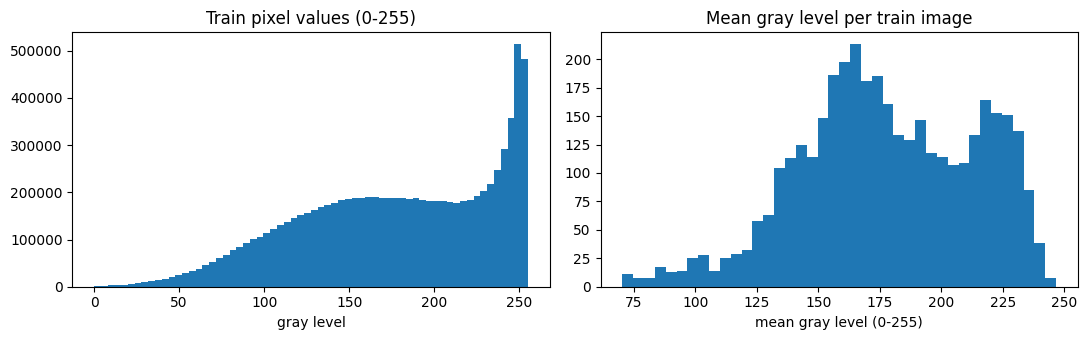


Saved /content/outputs/normalization.json


In [ ]:
# ---------------------------------------------------------------
# 1) Loading helper: grayscale + fixed-size resize
# ---------------------------------------------------------------
def load_gray_resized(path):
    """Read one image as 8-bit grayscale and resize it to the network input size."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)  # color is dropped, gray levels kept exactly as stored (0-255)
    if img is None:  # cv2.imread does not raise on failure, it returns None
        raise IOError(f"Could not read image: {path}")  # fail loudly with the offending path
    # Shrinking: INTER_AREA averages source pixels (no aliasing). Enlarging: INTER_LINEAR.
    # This is the usual OpenCV recommendation and it is deterministic, so train and inference match.
    interp = cv2.INTER_AREA if img.shape[0] > INPUT_H else cv2.INTER_LINEAR  # choose by direction of the resize
    return cv2.resize(img, (INPUT_W, INPUT_H), interpolation=interp)  # dsize is (width, height), not (h, w)


# ---------------------------------------------------------------
# 2) Load every image once and keep it in RAM
# ---------------------------------------------------------------
t0 = time.time()  # start a timer
# Stack all images into one array of shape (N, H, W), in the same row order as df.
# Because the order matches df, IMAGES[i] is the image of df.iloc[i], so the split indices
# from Cell 7 (idx_train, idx_val, idx_test) can index IMAGES directly.
IMAGES = np.stack([load_gray_resized(p) for p in df["img_path"]])  # uint8 keeps the cache small (about 13 MB)
print(f"Loaded {len(IMAGES)} images in {time.time() - t0:.1f}s | shape {IMAGES.shape} | dtype {IMAGES.dtype}")  # sanity print
assert IMAGES.shape == (len(df), INPUT_H, INPUT_W)  # one image per row, all the same size

# ---------------------------------------------------------------
# 3) Global mean/std from the TRAINING set only
# ---------------------------------------------------------------
# Why only train? Validation and test must behave like data the model has never seen.
# Computing statistics on them would let information about them leak into the pipeline.
# Why global (one mean and one std for the whole dataset) and not per image?
# Per-image normalization or histogram equalization would erase brightness differences
# between images, and here the gray level IS information (bright vs dark plates, etc.).
train_pixels = IMAGES[idx_train].astype(np.float64) / 255.0  # train images only, scaled from 0-255 to 0-1
MEAN = float(train_pixels.mean())  # average gray level over every training pixel
STD = float(train_pixels.std())  # spread of the gray levels over every training pixel
assert STD > 0, "Standard deviation is zero: images are constant?"  # would break the division below
print(f"\nTrain statistics (0-1 scale): mean = {MEAN:.4f} | std = {STD:.4f}")  # the two numbers we keep

# For comparison only (NOT used for anything): the held-out sets should look similar.
for name, idx in [("val", idx_val), ("test", idx_test)]:  # loop over the held-out splits
    pix = IMAGES[idx].astype(np.float64) / 255.0  # same scaling as above
    print(f"{name}: mean = {pix.mean():.4f} | std = {pix.std():.4f}")  # a large gap would signal a distribution shift

# ---------------------------------------------------------------
# 4) The normalization function used from now on
# ---------------------------------------------------------------
def normalize(x_uint8):
    """uint8 array (0-255) -> float32 with roughly zero mean and unit variance."""
    x = x_uint8.astype(np.float32) / 255.0  # scale to 0-1
    return (x - MEAN) / STD  # center and scale with the TRAIN statistics

check = normalize(IMAGES[idx_train])  # apply it to the training set as a check
print(f"After normalization (train): mean = {check.mean():.4f} | std = {check.std():.4f}")  # should be about 0 and 1
print(f"Value range after normalization: {check.min():.2f} to {check.max():.2f}")  # useful to know the input range

# ---------------------------------------------------------------
# 5) Look at the gray levels
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))  # two side-by-side plots
axes[0].hist(IMAGES[idx_train].ravel(), bins=64)  # distribution of every training pixel value
axes[0].set_title("Train pixel values (0-255)")  # what the left plot shows
axes[0].set_xlabel("gray level")  # x axis label
axes[1].hist(IMAGES[idx_train].reshape(len(idx_train), -1).mean(axis=1), bins=40)  # one mean per image
axes[1].set_title("Mean gray level per train image")  # what the right plot shows
axes[1].set_xlabel("mean gray level (0-255)")  # x axis label
plt.tight_layout()  # avoid overlapping labels
plt.show()  # draw the figure

# ---------------------------------------------------------------
# 6) Save the values: inference MUST use exactly the same ones
# ---------------------------------------------------------------
norm_info = {  # everything needed to reproduce the preprocessing later
    "mean": MEAN,  # train mean on the 0-1 scale
    "std": STD,  # train std on the 0-1 scale
    "input_w": INPUT_W,  # network input width
    "input_h": INPUT_H,  # network input height
    "n_train_images": int(len(idx_train)),  # how many images the statistics came from
    "resize": "INTER_AREA when shrinking, INTER_LINEAR when enlarging",  # resize rule used
}
with open(OUTPUT_DIR / "normalization.json", "w") as f:  # open the output file
    json.dump(norm_info, f, indent=2)  # write the values as readable JSON
print(f"\nSaved {OUTPUT_DIR / 'normalization.json'}")  # confirm the location

## 9 - Dataset and DataLoaders

In [ ]:
# ---------------------------------------------------------------
# 1) Dataset: what the model sees for one sample
# ---------------------------------------------------------------
class PlateCharDataset(Dataset):  # a PyTorch Dataset must implement __len__ and __getitem__
    """Holds normalized grayscale crops (1 x H x W) and their class indices."""

    def __init__(self, images_u8, y):  # images_u8: (N, H, W) uint8 from Cell 8, y: (N,) class indices
        # Normalize ONCE here instead of at every access: the data is small, so it is cheaper
        # to keep the ready-to-use float tensors in RAM (about 50 MB for the whole dataset).
        x = normalize(images_u8)  # Cell 8 function: /255, then (x - MEAN) / STD, float32 numpy
        self.x = torch.from_numpy(x).unsqueeze(1)  # add the channel dimension: (N, H, W) -> (N, 1, H, W)
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))  # CrossEntropyLoss expects int64 targets

    def __len__(self):  # how many samples there are
        return len(self.y)  # DataLoader uses this to know the epoch size

    def __getitem__(self, i):  # return the i-th sample
        # NO augmentation in this version. When it is added later, this is the place: it runs
        # at every access, so each epoch would see a slightly different version of the image.
        # Remember the vertical position of the pixels is signal: only tiny shifts are safe.
        return self.x[i], self.y[i]  # (1, H, W) float32 image and its class index


# Build one Dataset per split. IMAGES and df share the same row order, and idx_* hold row positions.
train_ds = PlateCharDataset(IMAGES[idx_train], df.loc[idx_train, "y"].to_numpy())  # training samples
val_ds = PlateCharDataset(IMAGES[idx_val], df.loc[idx_val, "y"].to_numpy())  # validation samples
test_ds = PlateCharDataset(IMAGES[idx_test], df.loc[idx_test, "y"].to_numpy())  # test samples
print(f"Samples -> train: {len(train_ds)} | val: {len(val_ds)} | test: {len(test_ds)}")  # sizes per split

# ---------------------------------------------------------------
# 2) DataLoaders: batching and shuffling
# ---------------------------------------------------------------
g = torch.Generator().manual_seed(SEED)  # dedicated random generator so the shuffle order is reproducible

train_loader = DataLoader(
    train_ds,  # the dataset to draw from
    batch_size=BATCH_SIZE,  # samples per training step
    shuffle=True,  # new random order every epoch, so the model does not learn the order
    drop_last=True,  # drop the incomplete last batch: tiny batches make BatchNorm statistics noisy
    generator=g,  # use the seeded generator for the shuffling
    num_workers=NUM_WORKERS,  # 0 = load in the main process (data is already in RAM)
    pin_memory=DEVICE.type == "cuda",  # speeds up CPU -> GPU copies
)
val_loader = DataLoader(
    val_ds,  # validation dataset
    batch_size=BATCH_SIZE * 2,  # no gradients are stored in evaluation, so bigger batches fit
    shuffle=False,  # fixed order: predictions line up with idx_val row by row
    num_workers=NUM_WORKERS,  # same loading mode as above
    pin_memory=DEVICE.type == "cuda",  # same transfer speed-up
)
test_loader = DataLoader(
    test_ds,  # test dataset
    batch_size=BATCH_SIZE * 2,  # larger batches for evaluation
    shuffle=False,  # fixed order: predictions line up with idx_test row by row
    num_workers=NUM_WORKERS,  # same loading mode as above
    pin_memory=DEVICE.type == "cuda",  # same transfer speed-up
)
print(f"Batches per epoch -> train: {len(train_loader)} | val: {len(val_loader)} | test: {len(test_loader)}")  # loop lengths

# ---------------------------------------------------------------
# 3) Sanity check on one batch
# ---------------------------------------------------------------
xb, yb = next(iter(train_loader))  # pull a single batch of training data
print(f"\nBatch images: shape {tuple(xb.shape)} | dtype {xb.dtype}")  # expect (BATCH_SIZE, 1, INPUT_H, INPUT_W) float32
print(f"Batch values: min {xb.min():.2f} | max {xb.max():.2f} | mean {xb.mean():.2f} | std {xb.std():.2f}")  # mean/std near 0/1
print(f"Batch labels: shape {tuple(yb.shape)} | dtype {yb.dtype} | min {yb.min()} | max {yb.max()}")  # expect int64 in 0..35
assert xb.shape == (BATCH_SIZE, 1, INPUT_H, INPUT_W)  # exact shape the network expects
assert set(yb.tolist()) <= set(ACTIVE_IDX)  # every label belongs to an active class (Cell 6)
g.manual_seed(SEED)  # reset the generator: the check above consumed one shuffle, this keeps training reproducible

# Look at the batch: the most important check is that each image matches its label.
n_show = 16  # how many images to display
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))  # a 2 x 8 grid
for ax, img, lab in zip(axes.ravel(), xb[:n_show], yb[:n_show]):  # one axis per image
    shown = (img[0].numpy() * STD + MEAN) * 255  # undo the normalization to see the original gray levels
    ax.imshow(shown, cmap="gray", vmin=0, vmax=255)  # fixed range keeps the true brightness
    ax.set_title(IDX_TO_CLASS[int(lab)], fontsize=11)  # decoded class letter/digit above the image
    ax.axis("off")  # hide the axes
plt.tight_layout()  # avoid overlapping titles
plt.show()  # draw the figure